<a href="https://colab.research.google.com/github/814725243117-netizen/Data-Analytics-Projects/blob/main/Credit_Card_Transaction_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

data = {
    "transaction_id": range(1, 16),
    "customer_id": [
        "C101", "C102", "C103", "C101", "C104",
        "C105", "C102", "C106", "C103", "C104",
        "C101", "C105", "C106", "C102", "C103"
    ],
    "transaction_date": [
        "2026-01-05", "2026-01-08", "2026-01-12",
        "2026-01-15", "2026-01-20", "2026-02-02",
        "2026-02-05", "2026-02-10", "2026-02-14",
        "2026-02-18", "2026-03-01", "2026-03-05",
        "2026-03-10", "2026-03-15", "2026-03-20"
    ],
    "category": [
        "Food", "Shopping", "Travel", "Food", "Electronics",
        "Shopping", "Food", "Travel", "Food", "Shopping",
        "Electronics", "Food", "Shopping", "Travel", "Food"
    ],
    "amount": [
        500, 2500, 1800, 350, 6000,
        1200, 450, 2200, 650, 3000,
        4500, 700, 1600, 1900, 550
    ]
}

df = pd.DataFrame(data)

df.to_csv("credit_card_transactions.csv", index=False)

print("Dataset created successfully!")
display(df.head())

Dataset created successfully!


,transaction_id,customer_id,transaction_date,category,amount
0,1,C101,2026-01-05,Food,500
1,2,C102,2026-01-08,Shopping,2500
2,3,C103,2026-01-12,Travel,1800
3,4,C101,2026-01-15,Food,350
4,5,C104,2026-01-20,Electronics,6000


In [2]:
# Total number of transactions
total_transactions = len(df)

# Total spending
total_spending = df["amount"].sum()

# Average transaction amount
average_spending = df["amount"].mean()

print("CREDIT CARD TRANSACTION ANALYSIS")
print("--------------------------------")
print("Total Transactions:", total_transactions)
print("Total Spending: ₹", total_spending)
print("Average Transaction: ₹", round(average_spending, 2))

# Display dataset information
display(df.head(10))

CREDIT CARD TRANSACTION ANALYSIS
--------------------------------
Total Transactions: 15
Total Spending: ₹ 27900
Average Transaction: ₹ 1860.0


,transaction_id,customer_id,transaction_date,category,amount
0,1,C101,2026-01-05,Food,500
1,2,C102,2026-01-08,Shopping,2500
2,3,C103,2026-01-12,Travel,1800
3,4,C101,2026-01-15,Food,350
4,5,C104,2026-01-20,Electronics,6000
5,6,C105,2026-02-02,Shopping,1200
6,7,C102,2026-02-05,Food,450
7,8,C106,2026-02-10,Travel,2200
8,9,C103,2026-02-14,Food,650
9,10,C104,2026-02-18,Shopping,3000


Category-wise Spending:
category
Electronics    10500
Food            3200
Shopping        8300
Travel          5900
Name: amount, dtype: int64


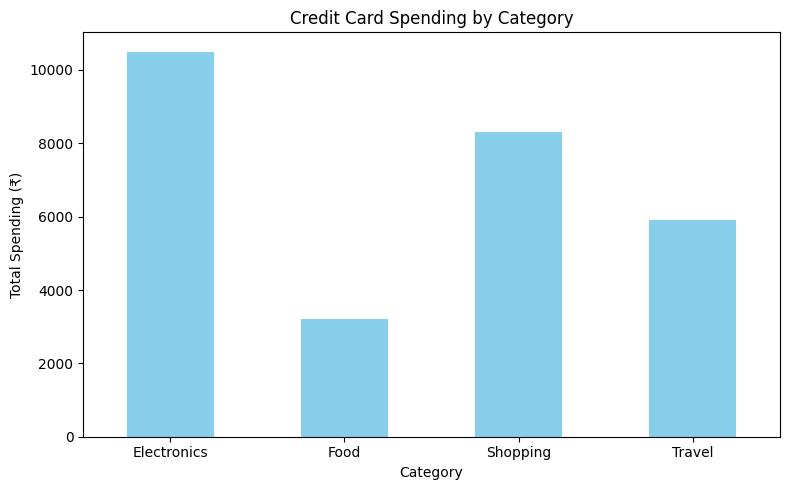

In [3]:
import matplotlib.pyplot as plt

# Calculate spending by category
category_spending = df.groupby("category")["amount"].sum()

print("Category-wise Spending:")
print(category_spending)

# Create bar chart
category_spending.plot(
    kind="bar",
    color="skyblue",
    figsize=(8, 5)
)

plt.title("Credit Card Spending by Category")
plt.xlabel("Category")
plt.ylabel("Total Spending (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Monthly Spending Analysis:
month
February     7500
January     11150
March        9250
Name: amount, dtype: int64


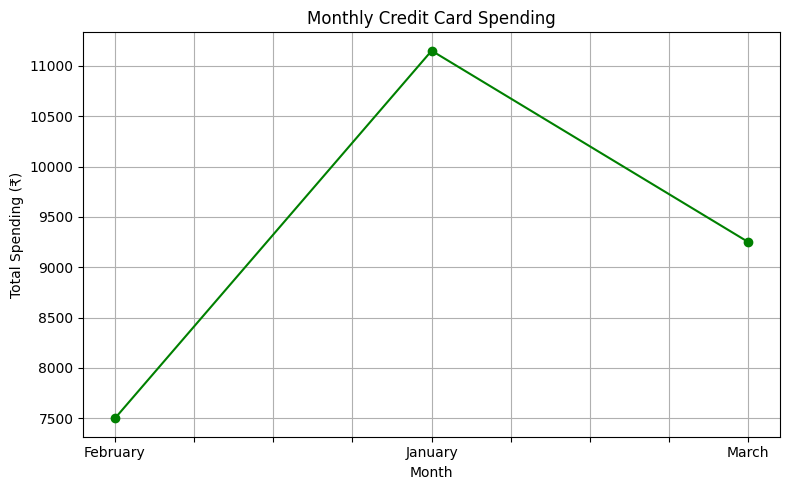

In [4]:
# Convert transaction date to datetime
df["transaction_date"] = pd.to_datetime(
    df["transaction_date"]
)

# Extract month
df["month"] = df["transaction_date"].dt.strftime("%B")

# Calculate monthly spending
monthly_spending = df.groupby("month")["amount"].sum()

print("Monthly Spending Analysis:")
print(monthly_spending)

# Create line chart
monthly_spending.plot(
    kind="line",
    marker="o",
    color="green",
    figsize=(8, 5)
)

plt.title("Monthly Credit Card Spending")
plt.xlabel("Month")
plt.ylabel("Total Spending (₹)")
plt.grid(True)
plt.tight_layout()
plt.show()

Customer-wise Spending:
customer_id
C104    9000
C101    5350
C102    4850
C106    3800
C103    3000
C105    1900
Name: amount, dtype: int64

Top 5 Customers:
customer_id
C104    9000
C101    5350
C102    4850
C106    3800
C103    3000
Name: amount, dtype: int64


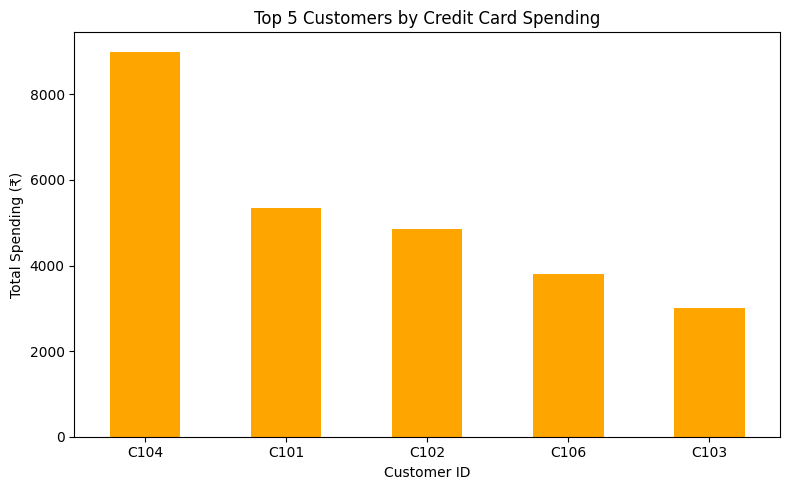

In [5]:
# Calculate total spending for each customer
customer_spending = (
    df.groupby("customer_id")["amount"]
    .sum()
    .sort_values(ascending=False)
)

print("Customer-wise Spending:")
print(customer_spending)

# Display top 5 customers
top_customers = customer_spending.head(5)

print("\nTop 5 Customers:")
print(top_customers)

# Create bar chart
top_customers.plot(
    kind="bar",
    color="orange",
    figsize=(8, 5)
)

plt.title("Top 5 Customers by Credit Card Spending")
plt.xlabel("Customer ID")
plt.ylabel("Total Spending (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Transactions by Day:
day
Thursday     4
Monday       3
Tuesday      3
Sunday       2
Saturday     1
Wednesday    1
Friday       1
Name: count, dtype: int64


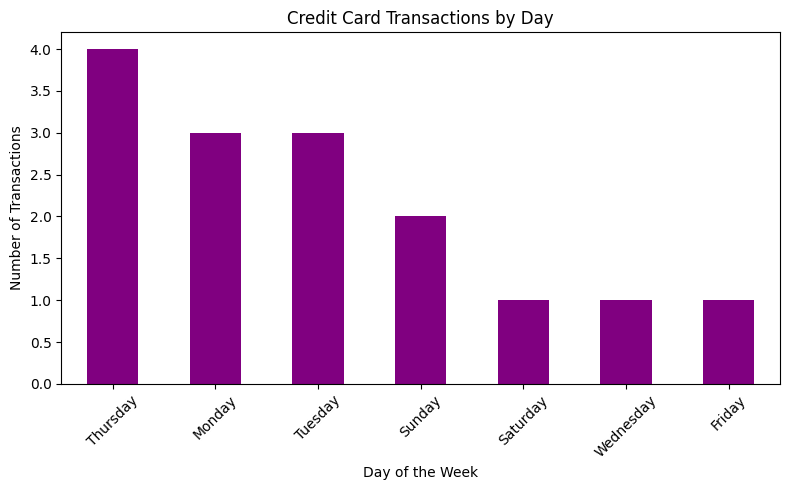

In [6]:
# Convert transaction date to day name
df["day"] = df["transaction_date"].dt.day_name()

# Count transactions by day
day_transactions = df["day"].value_counts()

print("Transactions by Day:")
print(day_transactions)

# Create bar chart
day_transactions.plot(
    kind="bar",
    color="purple",
    figsize=(8, 5)
)

plt.title("Credit Card Transactions by Day")
plt.xlabel("Day of the Week")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

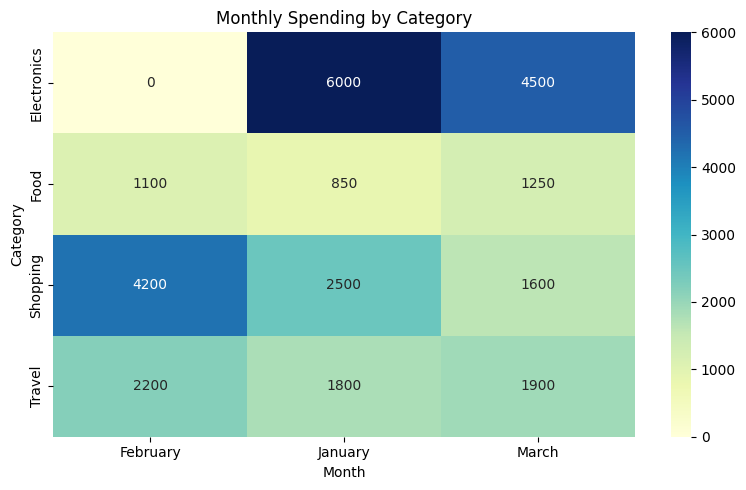

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a month and category spending table
spending_pivot = df.pivot_table(
    index="category",
    columns="month",
    values="amount",
    aggfunc="sum",
    fill_value=0
)

# Plot heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(
    spending_pivot,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("Monthly Spending by Category")
plt.xlabel("Month")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [8]:
# Credit Card Transaction Analysis Dashboard

total_transactions = len(df)
total_spending = df["amount"].sum()
average_spending = df["amount"].mean()

top_category = (
    df.groupby("category")["amount"]
    .sum()
    .idxmax()
)

top_customer = (
    df.groupby("customer_id")["amount"]
    .sum()
    .idxmax()
)

monthly_spending = df.groupby("month")["amount"].sum()
highest_month = monthly_spending.idxmax()

print("=" * 45)
print(" CREDIT CARD TRANSACTION ANALYSIS")
print("=" * 45)

print(f"Total Transactions : {total_transactions}")
print(f"Total Spending     : ₹{total_spending:,.2f}")
print(f"Average Spending   : ₹{average_spending:,.2f}")
print(f"Top Spending Category : {top_category}")
print(f"Highest Spending Customer : {top_customer}")
print(f"Highest Spending Month : {highest_month}")

print("=" * 45)
print("Dashboard Summary Generated Successfully!")

 CREDIT CARD TRANSACTION ANALYSIS
Total Transactions : 15
Total Spending     : ₹27,900.00
Average Spending   : ₹1,860.00
Top Spending Category : Electronics
Highest Spending Customer : C104
Highest Spending Month : January
Dashboard Summary Generated Successfully!


In [9]:
import os
import matplotlib.pyplot as plt

# Create a folder for project outputs
os.makedirs("Credit_Card_Project", exist_ok=True)

# Save the dataset
df.to_csv(
    "Credit_Card_Project/credit_card_transactions.csv",
    index=False
)

# Save the analysis summary
summary = pd.DataFrame({
    "Metric": [
        "Total Transactions",
        "Total Spending",
        "Average Transaction Amount"
    ],
    "Value": [
        len(df),
        df["amount"].sum(),
        round(df["amount"].mean(), 2)
    ]
})

summary.to_csv(
    "Credit_Card_Project/analysis_summary.csv",
    index=False
)

# Save monthly spending chart
plt.figure(figsize=(8, 5))
df.groupby("month")["amount"].sum().plot(
    kind="line", marker="o", color="green"
)
plt.title("Monthly Credit Card Spending")
plt.xlabel("Month")
plt.ylabel("Amount (₹)")
plt.tight_layout()
plt.savefig(
    "Credit_Card_Project/monthly_spending.png",
    dpi=300
)
plt.close()

print("Project files saved successfully!")
print("Dataset, summary and chart are ready.")

Project files saved successfully!
Dataset, summary and chart are ready.


In [13]:
import shutil
from google.colab import files

shutil.make_archive(
    "Credit_Card_Project",
    "zip",
    "Credit_Card_Project"
)

files.download("Credit_Card_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
report = f"""
CREDIT CARD TRANSACTION AND SPENDING ANALYSIS
==============================================

1. INTRODUCTION
This project analyzes credit card transactions
and customer spending patterns using Python.

2. OBJECTIVES
- Analyze total credit card spending.
- Identify category-wise expenses.
- Analyze monthly spending trends.
- Identify top spending customers.
- Study transaction patterns.

3. TOOLS USED
- Python
- Pandas
- Matplotlib
- Seaborn
- Google Colab

4. DATASET SUMMARY
Total Transactions: {len(df)}
Total Spending: Rs. {df['amount'].sum():,.2f}
Average Transaction: Rs. {df['amount'].mean():,.2f}

5. ANALYSIS PERFORMED
- Category-wise Spending Analysis
- Monthly Spending Analysis
- Top Customers Analysis
- Day-wise Transaction Analysis
- Spending Pattern Heatmap

6. CONCLUSION
This project demonstrates how Python can be used
to analyze credit card transaction data and
understand customer spending behavior.

Note: The analysis uses sample data created
for educational purposes.
"""

with open(
    "Credit_Card_Project/Project_Report.txt",
    "w"
) as file:
    file.write(report)

print("Project report created successfully!")

Project report created successfully!


In [18]:
import shutil
from google.colab import files

# Add the report to the project folder
shutil.make_archive(
    "Credit_Card_Project_Final",
    "zip",
    "Credit_Card_Project"
)

# Download the final project
files.download("Credit_Card_Project_Final.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>